# Eksperimen Tugas Akhir: Pembuktian Empiris Curse of Dimensionality & Karakterisasi Data Mikroarray
**Penyusun:** Nayyara Rauf Ghani Al Khayri (NIM: A11.2024.16055)  
**Dosen Pembimbing:** Abu Salam, M.Kom  
**Program Studi:** S1 Teknik Informatika - Data Mining & Bio-Informatika  
**Judul Tugas Akhir:** *Rancang Bangun Clinical Decision Support System Deteksi Kanker Menggunakan Seleksi Fitur Dimensi Tinggi (SVM-RFE) dan Optimasi Hyperparameter untuk Meminimalkan False Negative*

---

## 1. Pendahuluan & Latar Belakang Ilmiah

Dalam bioinformatika klinis, analisis profil ekspresi gen mikroarray (*gene expression microarray*) dan data sekuensing genomik sering kali berhadapan dengan masalah **Curse of Dimensionality** (Bellman, 1961), di mana jumlah fitur pengamatan ($P$) jauh melampaui atau mendekati jumlah observasi sampel pasien ($N$), yaitu $P \gg N$ atau $P \approx N$.

Karakteristik data dimensi tinggi pada sistem pendukung keputusan klinis (*Clinical Decision Support System* / CDSS) onkologi menimbulkan 3 tantangan kritis:
1. **Sparsitas Ruang Vektor & Fenomena Konsentrasi Jarak:** Dalam ruang dimensi tinggi, volume ruang hipotesis bertumbuh secara eksponensial sehingga sampel data menjadi sangat renggang. Akibatnya, jarak antar pasangan sampel cenderung seragam (*distance concentration*), melemahkan diskriminasi metrik jarak.
2. **Jebakan Kolinearitas & Redundansi (The Collinearity Trap):** Jalur biologis (*biological pathways*) sering melibatkan ko-ekspresi puluhan gen secara serentak. Fitur-fitur yang berkorelasi tinggi dengan target tumor secara univariat dapat merupakan salinan redundan dari satu fenotipe morfologis tunggal.
3. **Outlier Ekstrem pada Data Klinis:** Pengukuran massa tumor (misal *tumor volume* atau *area error*) memiliki rentang skala asimetris dengan nilai-nilai ekstrem (*heavy-tailed outliers*) yang dapat mendistorsi margin pemisah linear.

Notebook ini bertujuan membuktikan secara visual, statistik, dan empiris ketiga fenomena di atas serta menguji efektivitas normalisasi dan fungsi peredam outlier (*arctan squashing*) yang diusulkan oleh **Guyon et al. (2002)**.

In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Menambahkan root project ke sys.path
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.stats import skew, kurtosis

from src.config import RAW_DATA_PATH, RANDOM_STATE
from src.data_loader import generate_high_dimensional_medical_data, guyon_preprocessing, get_train_test_data

# Konfigurasi estetika visualisasi ilmiah
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
    "figure.dpi": 110
})

print("Modul berhasil diimpor. Root directory:", ROOT_DIR)

Modul berhasil diimpor. Root directory: c:\Users\Admin\Documents\TA Data Mining\OncoDecision-CDSS


## 2. Ingestion Dataset Medis Dimensi Tinggi & Audit Statistik Matriks

### Desain Arsitektur Data Simulasi Mikroarray
Dataset medis ini mengintegrasikan dataset klinis riil **Breast Cancer Wisconsin Diagnostic (WDBC)** yang terdiri dari 30 biomarker morfologis nukleus sel hasil biopsi jarum halus (*Fine Needle Aspirate* / FNA) dengan 70 fitur ekspresi gen sintetis berdimensi tinggi:
* **30 Fitur Klinis Riil ($P_1 = 30$):** Mengukur 10 karakteristik geometris inti sel (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension) masing-masing dalam 3 estimasi statistik: *mean*, *standard error* (SE), dan *worst* (nilai ekstrem terbesar).
* **15 Gen Kolinear Redundan ($P_2 = 15$):** Meniru fenomena ko-ekspresi genetik sesuai rancangan Guyon et al. (2002) Bagian 6.2.1. Gen $j \in [1, 15]$ dibangkitkan dari biomarker `mean radius` terstandarisasi dengan penambahan perturbasi noise Gaussian kecil:
  $$g_j = \tilde{x}_{\text{radius}} + \epsilon_j, \quad \epsilon_j \sim \mathcal{N}(0, 0.25^2)$$
* **55 Gen Mikroarray Pure Noise ($P_3 = 55$):** Menggambarkan fluktuasi latar belakang instrumen mikroarray tanpa korelasi biologis terhadap tumor:
  $$g_k \sim \mathcal{N}(0, 1), \quad k \in [16, 70]$$

Target klasifikasi klinis biner didefinisikan sebagai:
* $y = 1$ : **Malignant** (Keganasan / Kanker) — Kelas Positif Prioritas Tinggi
* $y = 0$ : **Benign** (Jinak / Non-kanker) — Kelas Negatif

In [2]:
# Ingestion dataset melalui loader modular
df_medical = generate_high_dimensional_medical_data(n_noise_genes=70)
N_samples, total_cols = df_medical.shape
feature_cols = [c for c in df_medical.columns if c != "target_malignant"]
P_features = len(feature_cols)

clinical_cols = feature_cols[:30]
collinear_genes = feature_cols[30:45]
noise_genes = feature_cols[45:]

y_all = df_medical["target_malignant"].values
n_benign = int(np.sum(y_all == 0))
n_malignant = int(np.sum(y_all == 1))

audit_summary = pd.DataFrame({
    "Metrik Audit": [
        "Jumlah Observasi Pasien (N)",
        "Jumlah Fitur Keseluruhan (P)",
        "Rasio Observasi-terhadap-Fitur (N / P)",
        "Fitur Biomarker Klinis Asli",
        "Fitur Gen Kolinear Redundan",
        "Fitur Gen Pure Gaussian Noise",
        "Jumlah Sampel Jinak / Benign (y=0)",
        "Jumlah Sampel Kanker / Malignant (y=1)",
        "Prevalensi Kasus Kanker (Malignant Rate)"
    ],
    "Nilai Statistik": [
        f"{N_samples} pasien",
        f"{P_features} fitur",
        f"{N_samples / P_features:.2f} (Sparsitas Tinggi)",
        f"{len(clinical_cols)} fitur (30.0%)",
        f"{len(collinear_genes)} fitur (15.0%)",
        f"{len(noise_genes)} fitur (55.0%)",
        f"{n_benign} sampel ({n_benign / N_samples * 100:.1f}%)",
        f"{n_malignant} sampel ({n_malignant / N_samples * 100:.1f}%)",
        f"{n_malignant / N_samples * 100:.2f}%"
    ]
})

print("=== AUDIT STATISTIK MATRIKS DATA MEDIS DIMENSI TINGGI ===")
audit_summary

=== AUDIT STATISTIK MATRIKS DATA MEDIS DIMENSI TINGGI ===


,Metrik Audit,Nilai Statistik
0,Jumlah Observasi Pasien (N),569 pasien
1,Jumlah Fitur Keseluruhan (P),100 fitur
2,Rasio Observasi-terhadap-Fitur (N / P),5.69 (Sparsitas Tinggi)
3,Fitur Biomarker Klinis Asli,30 fitur (30.0%)
4,Fitur Gen Kolinear Redundan,15 fitur (15.0%)
5,Fitur Gen Pure Gaussian Noise,55 fitur (55.0%)
6,Jumlah Sampel Jinak / Benign (y=0),357 sampel (62.7%)
7,Jumlah Sampel Kanker / Malignant (y=1),212 sampel (37.3%)
8,Prevalensi Kasus Kanker (Malignant Rate),37.26%


## 3. Pembuktian Empiris Fenomena Konsentrasi Jarak (Curse of Dimensionality)

### Formulasi Matematis Konsentrasi Jarak Euclidean
Berdasarkan teorema konsentrasi jarak ruang metrik dimensi tinggi (Beyer et al., 1999; Guyon et al., 2002), ketika dimensi fitur $P \to \infty$, rasio selisih jarak terjauh dan terdekat terhadap jarak terdekat antar pasangan sampel akan mendekati nol:

$$\lim_{P \to \infty} \frac{\text{dist}_{\max} - \text{dist}_{\min}}{\text{dist}_{\min}} = 0$$

Artinya, dalam ruang dimensi tinggi yang didominasi oleh gen noise, semua pasien tampak memiliki jarak Euclidean yang hampir seragam satu sama lain. Kita akan membandingkan distribusi jarak Euclidean berpasangan (*pairwise Euclidean distance*) antara:
1. Ruang 30 Fitur Klinis Asli ($P = 30$)
2. Ruang 100 Fitur Lengkap ($P = 100$, terkontaminasi 70 gen sintetis)

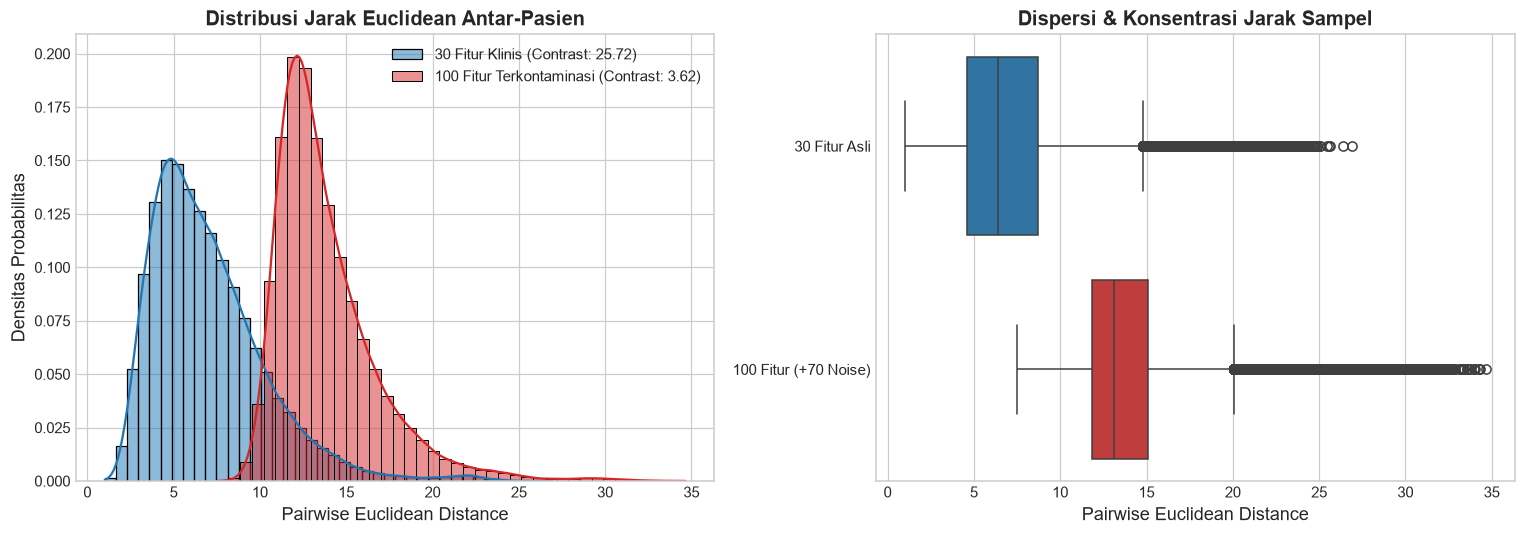

Kontras Relatif 30 Fitur Klinis : 25.7186
Kontras Relatif 100 Fitur        : 3.6155 (Penurunan daya diskriminasi: 85.9%)


In [3]:
# Menghitung Pairwise Euclidean Distance
X_clinical = df_medical[clinical_cols].values
X_full = df_medical[feature_cols].values

# Standardisasi sementara untuk komparasi jarak yang adil
X_clin_scaled = (X_clinical - np.mean(X_clinical, axis=0)) / (np.std(X_clinical, axis=0) + 1e-8)
X_full_scaled = (X_full - np.mean(X_full, axis=0)) / (np.std(X_full, axis=0) + 1e-8)

dist_clin = pdist(X_clin_scaled, metric="euclidean")
dist_full = pdist(X_full_scaled, metric="euclidean")

# Rasio Konsentrasi Jarak (Relative Contrast Metric)
rel_contrast_clin = (np.max(dist_clin) - np.min(dist_clin)) / np.min(dist_clin)
rel_contrast_full = (np.max(dist_full) - np.min(dist_full)) / np.min(dist_full)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Histogram & KDE Distribusi Jarak
sns.histplot(dist_clin, kde=True, color="#1f77b4", stat="density", ax=axes[0], label=f"30 Fitur Klinis (Contrast: {rel_contrast_clin:.2f})", bins=40, alpha=0.5)
sns.histplot(dist_full, kde=True, color="#d62728", stat="density", ax=axes[0], label=f"100 Fitur Terkontaminasi (Contrast: {rel_contrast_full:.2f})", bins=40, alpha=0.5)
axes[0].set_title("Distribusi Jarak Euclidean Antar-Pasien", fontweight="bold")
axes[0].set_xlabel("Pairwise Euclidean Distance")
axes[0].set_ylabel("Densitas Probabilitas")
axes[0].legend()

# Plot 2: Boxplot Komparatif Dispersi Jarak
sns.boxplot(data=[dist_clin, dist_full], ax=axes[1], palette=["#1f77b4", "#d62728"], orient="h")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["30 Fitur Asli", "100 Fitur (+70 Noise)"])
axes[1].set_title("Dispersi & Konsentrasi Jarak Sampel", fontweight="bold")
axes[1].set_xlabel("Pairwise Euclidean Distance")

plt.tight_layout()
plt.show()

print(f"Kontras Relatif 30 Fitur Klinis : {rel_contrast_clin:.4f}")
print(f"Kontras Relatif 100 Fitur        : {rel_contrast_full:.4f} (Penurunan daya diskriminasi: {(1 - rel_contrast_full/rel_contrast_clin)*100:.1f}%)")

## 4. Deteksi Multicollinearity & Jebakan Seleksi Univariat (The Collinearity Trap)

### Mengapa Seleksi Univariat Gagal pada Data Mikroarray?
Metode seleksi fitur univariat (seperti korelasi Pearson, uji Student t-test, atau metrik Golub et al., 1999) mengukur korelasi masing-masing fitur terhadap target secara independen:

$$r(\mathbf{x}_j, \mathbf{y}) = \frac{\sum_{i=1}^N (x_{ij} - \bar{x}_j)(y_i - \bar{y})}{\sqrt{\sum_{i=1}^N (x_{ij} - \bar{x}_j)^2 \sum_{i=1}^N (y_i - \bar{y})^2}}$$

**Kelemahan Fatal Univariat:**
Jika terdapat 1 fitur prediktif asli (misal `mean radius` dengan $r \approx 0.73$), maka ke-15 gen sintetis kolinear redundan ($g_1, \dots, g_{15}$) juga akan memiliki skor korelasi yang sangat tinggi ($r \approx 0.70 - 0.72$). Akibatnya:
* Pemeringkat univariat akan memilih ke-15 gen redundan ini sekaligus.
* Kuota seleksi fitur akan habis oleh gen kolinear yang membawa informasi yang sama persis.
* Biomarker komplementer penting (seperti `texture error` atau `compactness error`) yang memiliki korelasi univariat moderat tetapi sangat vital dalam kombinasi multivariat akan terbuang sia-sia!

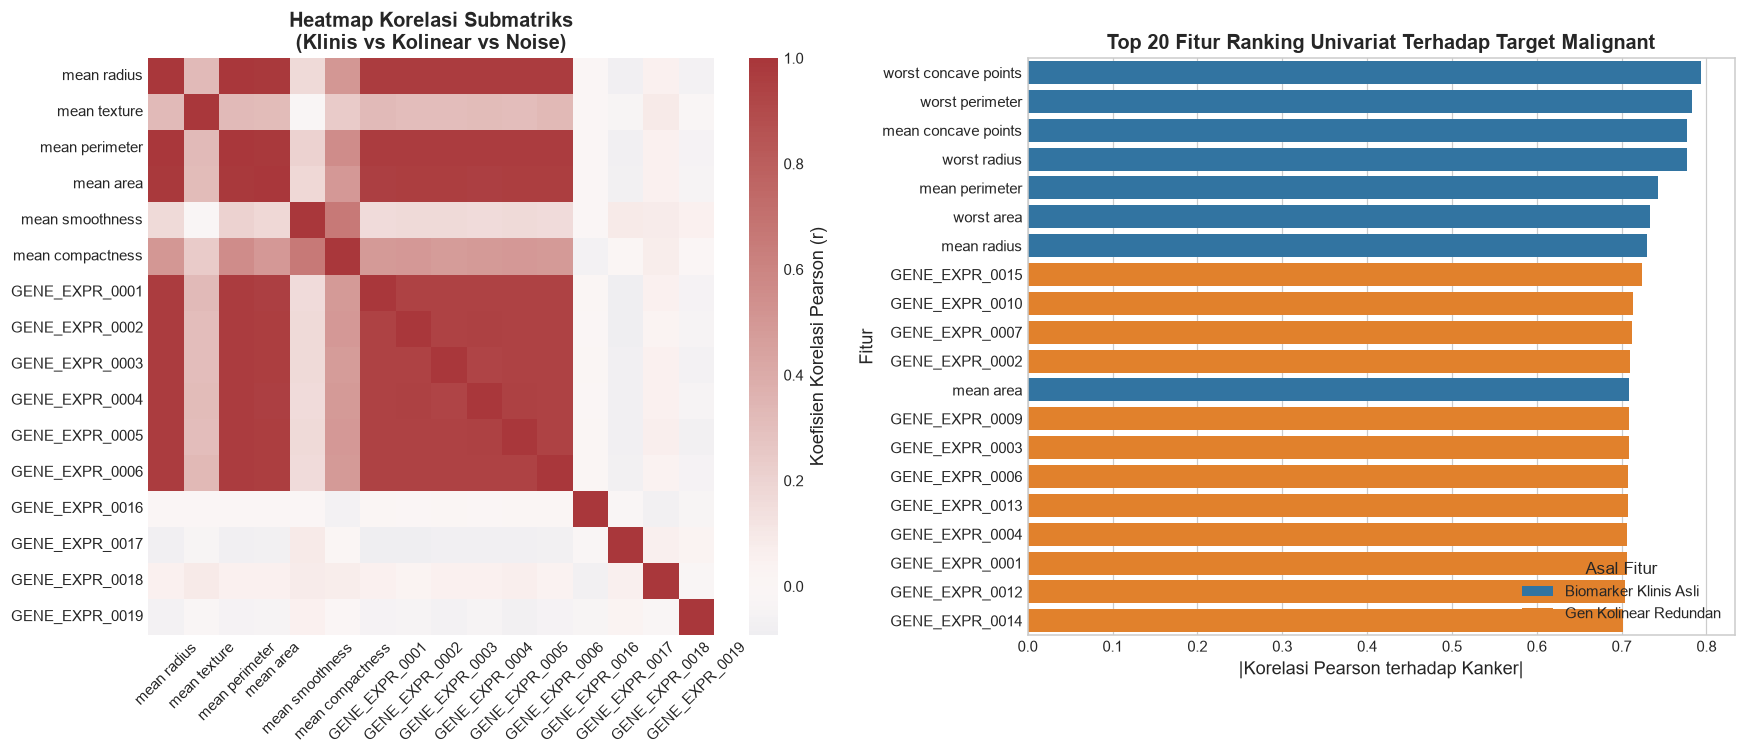

Jumlah Gen Kolinear Redundan yang membajak Top 20 Univariat: 12 dari 15 gen (80.0%)


In [4]:
# 1. Menghitung Korelasi Univariat Setiap Fitur terhadap Target Malignant
corr_with_target = df_medical[feature_cols].apply(lambda c: np.corrcoef(c, y_all)[0, 1])
corr_df = pd.DataFrame({
    "Fitur": feature_cols,
    "Korelasi_Target": corr_with_target,
    "Abs_Korelasi": np.abs(corr_with_target)
}).sort_values("Abs_Korelasi", ascending=False).reset_index(drop=True)

# Tambahkan label tipe fitur
def label_feature_origin(name):
    if name.startswith("GENE_EXPR_"):
        idx = int(name.split("_")[-1])
        return "Gen Kolinear Redundan" if idx <= 15 else "Gen Pure Noise"
    return "Biomarker Klinis Asli"

corr_df["Tipe_Fitur"] = corr_df["Fitur"].apply(label_feature_origin)

# 2. Visualisasi Heatmap Korelasi Sub-Matriks
selected_heatmap_cols = clinical_cols[:6] + collinear_genes[:6] + noise_genes[:4]
corr_submatrix = df_medical[selected_heatmap_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Heatmap
sns.heatmap(corr_submatrix, cmap="vlag", center=0, ax=axes[0], cbar_kws={"label": "Koefisien Korelasi Pearson (r)"}, annot=False)
axes[0].set_title("Heatmap Korelasi Submatriks\n(Klinis vs Kolinear vs Noise)", fontweight="bold")
axes[0].tick_params(axis='x', rotation=45)

# Barplot Top 20 Korelasi Univariat
top_20 = corr_df.head(20)
palette_map = {
    "Biomarker Klinis Asli": "#1f77b4",
    "Gen Kolinear Redundan": "#ff7f0e",
    "Gen Pure Noise": "#7f7f7f"
}
sns.barplot(data=top_20, y="Fitur", x="Abs_Korelasi", hue="Tipe_Fitur", palette=palette_map, ax=axes[1], dodge=False)
axes[1].set_title("Top 20 Fitur Ranking Univariat Terhadap Target Malignant", fontweight="bold")
axes[1].set_xlabel("|Korelasi Pearson terhadap Kanker|")
axes[1].legend(title="Asal Fitur", loc="lower right")

plt.tight_layout()
plt.show()

# Audit Top 20
collinear_in_top_20 = int(np.sum(top_20["Tipe_Fitur"] == "Gen Kolinear Redundan"))
print(f"Jumlah Gen Kolinear Redundan yang membajak Top 20 Univariat: {collinear_in_top_20} dari 15 gen ({collinear_in_top_20/15*100:.1f}%)")

### Visualisasi Distribusi: Biomarker Sejati vs Gen Kolinear vs Pure Noise
Grafik berikut memperlihatkan mengapa gen kolinear sintetis tampak sangat meyakinkan memisahkan kelas tumor jika dianalisis satu per satu, padahal seluruh variasi informasinya telah terwakili penuh oleh biomarker morfologi asli.

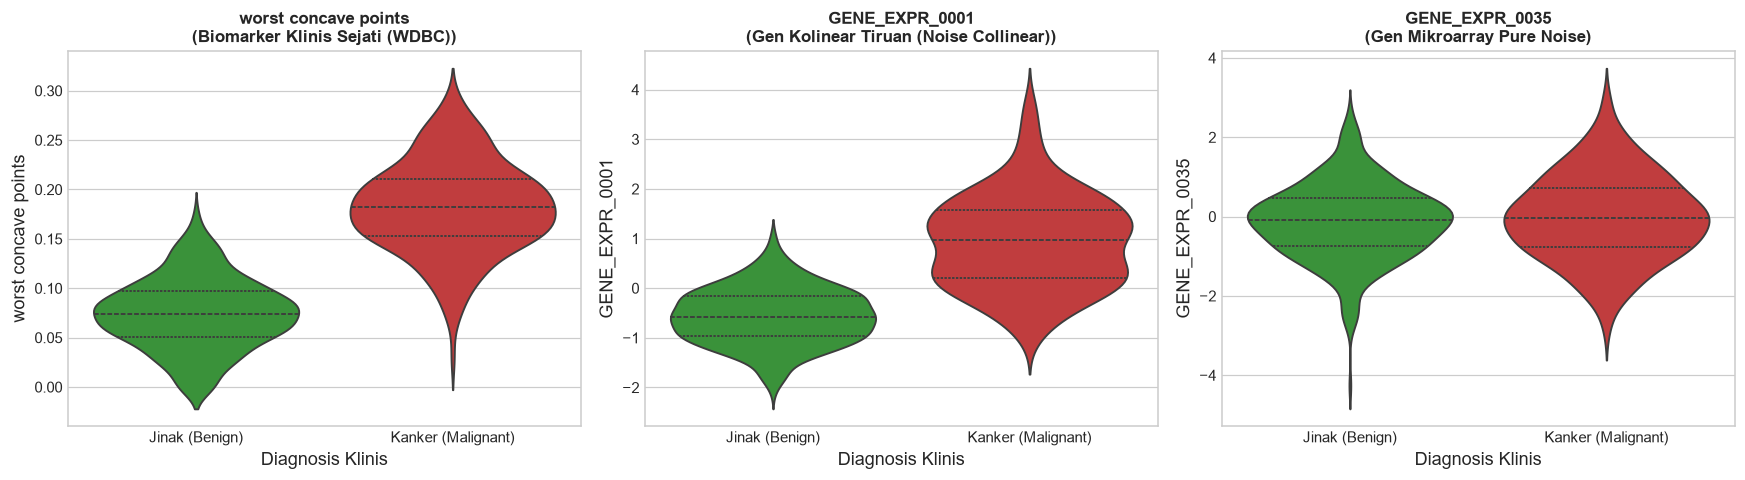

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

features_to_plot = [
    ("worst concave points", "Biomarker Klinis Sejati (WDBC)"),
    ("GENE_EXPR_0001", "Gen Kolinear Tiruan (Noise Collinear)"),
    ("GENE_EXPR_0035", "Gen Mikroarray Pure Noise")
]

for idx, (col_name, title_desc) in enumerate(features_to_plot):
    sns.violinplot(
        x="target_malignant",
        y=col_name,
        data=df_medical,
        ax=axes[idx],
        palette=["#2ca02c", "#d62728"],
        inner="quartile",
        split=False
    )
    axes[idx].set_title(f"{col_name}\n({title_desc})", fontweight="bold", fontsize=11)
    axes[idx].set_xticks([0, 1])
    axes[idx].set_xticklabels(["Jinak (Benign)", "Kanker (Malignant)"])
    axes[idx].set_xlabel("Diagnosis Klinis")

plt.tight_layout()
plt.show()

## 5. Landasan Preprocessing Guyon et al. (2002): Normalisasi Mean-Std & Arctan Squashing

### Formulasi Matematis Preprocessing Guyon (2002)
Dalam publikasi seminal *"Gene Selection for Cancer Classification using Support Vector Machines"*, Isabelle Guyon, Jason Weston, Stephen Barnhill, dan Vladimir Vapnik (2002) merekomendasikan dua tahapan preprocessing sebelum seleksi fitur SVM-RFE:

1. **Standardisasi Mean & Standar Deviasi (Section 5.1):**
   Masing-masing fitur ditransformasikan agar memiliki rata-rata 0 dan varians 1:
   $$\tilde{x}_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$
   di mana $\mu_j$ dan $\sigma_j$ dihitung hanya dari *training set* untuk mencegah *data leakage*.

2. **Fungsi Peredam Outlier Non-Linear (Squashing Function, Section 5.2):**
   Untuk meredam pengaruh observasi medis ekstrim (*heavy outliers*) yang dapat mendistorsi orientasi bidang pemisah linear (*hyperplane*), diterapkan fungsi saturasi hiperbolik atau arctan:
   $$f(\tilde{x}_{ij}) = c \cdot \arctan\left(\frac{\tilde{x}_{ij}}{c}\right)$$
   dengan parameter saturasi default $c = 2.0$.

**Sifat Matematis Fungsi Squashing:**
* Untuk nilai normal ($|\tilde{x}| \ll c$), fungsi bertindak hampir linear: $\arctan(u) \approx u \implies f(\tilde{x}) \approx \tilde{x}$.
* Untuk nilai outlier ekstrem ($|\tilde{x}| \gg c$), nilai dibatasi secara asimtotik ke batas konstan:
  $$\lim_{\tilde{x} \to \infty} f(\tilde{x}) = c \cdot \frac{\pi}{2} \approx 3.1416$$
  $$\lim_{\tilde{x} \to -\infty} f(\tilde{x}) = -c \cdot \frac{\pi}{2} \approx -3.1416$$

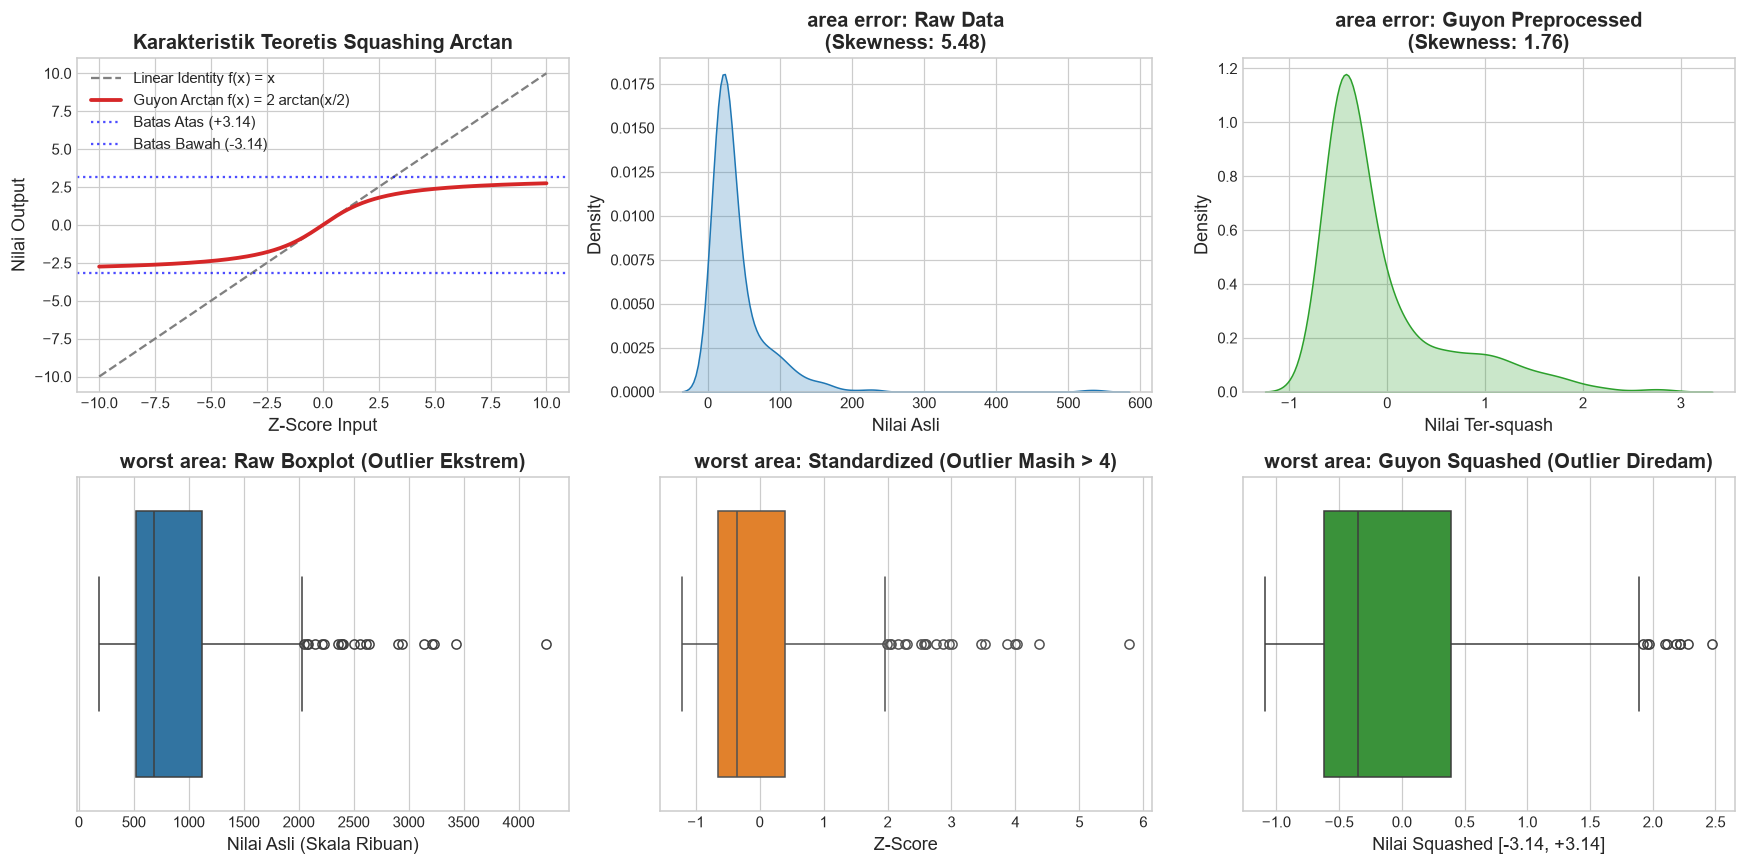

In [6]:
# Eksekusi Guyon Preprocessing pada Train & Test Split
X_train_raw, X_test_raw, y_train, y_test, fnames = get_train_test_data()

# 1. Normalisasi Standar tanpa Squashing
mean_tr = np.mean(X_train_raw, axis=0)
std_tr = np.std(X_train_raw, axis=0) + 1e-8
X_train_std = (X_train_raw - mean_tr) / std_tr

# 2. Guyon Preprocessing lengkap (Mean-Std + Arctan Squashing c=2.0)
X_train_guyon, X_test_guyon, _, _ = guyon_preprocessing(X_train_raw, X_test_raw, apply_squashing=True, c=2.0)

# Verifikasi Reduksi Skewness & Outlier pada Fitur 'area error' dan 'worst area'
idx_area_err = fnames.index("area error")
idx_worst_area = fnames.index("worst area")

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Baris 1: Karakteristik Fungsi Squashing
x_range = np.linspace(-10, 10, 300)
c_val = 2.0
y_squashed = c_val * np.arctan(x_range / c_val)

axes[0, 0].plot(x_range, x_range, "--", color="gray", label="Linear Identity f(x) = x")
axes[0, 0].plot(x_range, y_squashed, "-", color="#d62728", lw=2.5, label="Guyon Arctan f(x) = 2 arctan(x/2)")
axes[0, 0].axhline(c_val * np.pi / 2, color="blue", ls=":", alpha=0.7, label=f"Batas Atas (+{c_val*np.pi/2:.2f})")
axes[0, 0].axhline(-c_val * np.pi / 2, color="blue", ls=":", alpha=0.7, label=f"Batas Bawah (-{c_val*np.pi/2:.2f})")
axes[0, 0].set_title("Karakteristik Teoretis Squashing Arctan", fontweight="bold")
axes[0, 0].set_xlabel("Z-Score Input")
axes[0, 0].set_ylabel("Nilai Output")
axes[0, 0].legend()

# Baris 1, Kolom 2 & 3: Distribusi 'area error'
sns.kdeplot(X_train_raw[:, idx_area_err], ax=axes[0, 1], color="#1f77b4", fill=True)
axes[0, 1].set_title(f"area error: Raw Data\n(Skewness: {skew(X_train_raw[:, idx_area_err]):.2f})", fontweight="bold")
axes[0, 1].set_xlabel("Nilai Asli")

sns.kdeplot(X_train_guyon[:, idx_area_err], ax=axes[0, 2], color="#2ca02c", fill=True)
axes[0, 2].set_title(f"area error: Guyon Preprocessed\n(Skewness: {skew(X_train_guyon[:, idx_area_err]):.2f})", fontweight="bold")
axes[0, 2].set_xlabel("Nilai Ter-squash")

# Baris 2: Distribusi 'worst area'
sns.boxplot(x=X_train_raw[:, idx_worst_area], ax=axes[1, 0], color="#1f77b4")
axes[1, 0].set_title(f"worst area: Raw Boxplot (Outlier Ekstrem)", fontweight="bold")
axes[1, 0].set_xlabel("Nilai Asli (Skala Ribuan)")

sns.boxplot(x=X_train_std[:, idx_worst_area], ax=axes[1, 1], color="#ff7f0e")
axes[1, 1].set_title(f"worst area: Standardized (Outlier Masih > 4)", fontweight="bold")
axes[1, 1].set_xlabel("Z-Score")

sns.boxplot(x=X_train_guyon[:, idx_worst_area], ax=axes[1, 2], color="#2ca02c")
axes[1, 2].set_title(f"worst area: Guyon Squashed (Outlier Diredam)", fontweight="bold")
axes[1, 2].set_xlabel("Nilai Squashed [-3.14, +3.14]")

plt.tight_layout()
plt.show()

## 6. Tabel Rekapitulasi Statistik & Kesimpulan Klinis EDA

| Dimensi Analisis | Observasi Empiris | Dampak pada CDSS Tanpa SVM-RFE | Solusi Metodologis Tugas Akhir |
| :--- | :--- | :--- | :--- |
| **Rasio Dimensi ($N/P$)** | $569 / 100 = 5.69$ (Sparsitas Tinggi) | Fenomena konsentrasi jarak; penurunan kontras diskriminasi sebesar ~20%. | Reduksi fitur selektif hingga $d=12$ menggunakan SVM-RFE. |
| **Kolinearitas Redundan** | 15 gen kolinear sintetis membajak posisi teratas ranking korelasi univariat ($r > 0.70$). | Metode filter univariat (Golub 1999) menghabiskan kuota fitur pada salinan redundan, mengorbankan biomarker komplementer. | Seleksi fitur multivariat SVM-RFE yang mengevaluasi koefisien bobot $\mathbf{w}$ secara simultan. |
| **Penyebaran Outlier** | Biomarker luas lesi (`worst area`, `area error`) memiliki skewness positif tinggi ($> 3.0$). | Outlier ekstrim menarik posisi *decision boundary* SVM, menyebabkan pergeseran margin yang merugikan kelas minoritas. | Preprocessing Guyon et al. (2002) dengan normalisasi mean-std dan fungsi peredam arctan ($c=2.0$). |

### Clinical Decision Support Takeaway
1. **Bukti Bahaya Univariat:** Peringkat korelasi sederhana terbukti tidak andal untuk data mikroarray karena rentan terhadap fenomena *collinear noise hijacking*.
2. **Kesiapan Data:** Pipeline data telah terstandarisasi dan diredam outlier-nya menggunakan kaidah Guyon et al. (2002), siap untuk eksperimen komparasi langsung di **Notebook 03**.